# TECH 405 — RNN Hackathon: AG News Topic Classification with an LSTM

**Goal:** build a working LSTM classifier (`nn.Embedding → nn.LSTM → nn.Linear`) on **AG News** (4 topic classes) and report test accuracy.

| Dataset | Task (classes) | Baseline (majority class) | Target |
|---|---|---|---|
| AG News | topic (4) | 25% | 88% |

**Notebook outline**
1. Setup & data loading
2. Quick EDA + majority-class baseline
3. Text preprocessing (tokenise → vocabulary → integer sequences)
4. **LSTM** (main submission, no pretrained weights)
5. Results summary vs. baseline / target

## 1. Setup

In [1]:
import re, json, time, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.7.1+cu118 | device: cuda


## 2. Load AG News
Columns: `0` = class (1–4), `1` = title, `2` = description. The official test split from the same repository is used for the final test accuracy.

In [2]:
BASE = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/"
df = pd.read_csv(BASE + "train.csv", header=None)
test_df = pd.read_csv(BASE + "test.csv", header=None)
df.columns = test_df.columns = ["label", "title", "description"]

CLASS_NAMES = ["World", "Sports", "Business", "Sci/Tech"]
for d in (df, test_df):
    d["label"] = d["label"] - 1                      # 1..4  ->  0..3
    d["text"] = d["title"] + " " + d["description"]

print("train:", df.shape, " test:", test_df.shape)
df.head()

train: (120000, 4)  test: (7600, 4)


,label,title,description,text
0,2,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli...",Wall St. Bears Claw Back Into the Black (Reute...
1,2,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...,Carlyle Looks Toward Commercial Aerospace (Reu...
2,2,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...,Oil and Economy Cloud Stocks' Outlook (Reuters...
3,2,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...,Iraq Halts Oil Exports from Main Southern Pipe...
4,2,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco...","Oil prices soar to all-time record, posing new..."


### Quick EDA & majority-class baseline

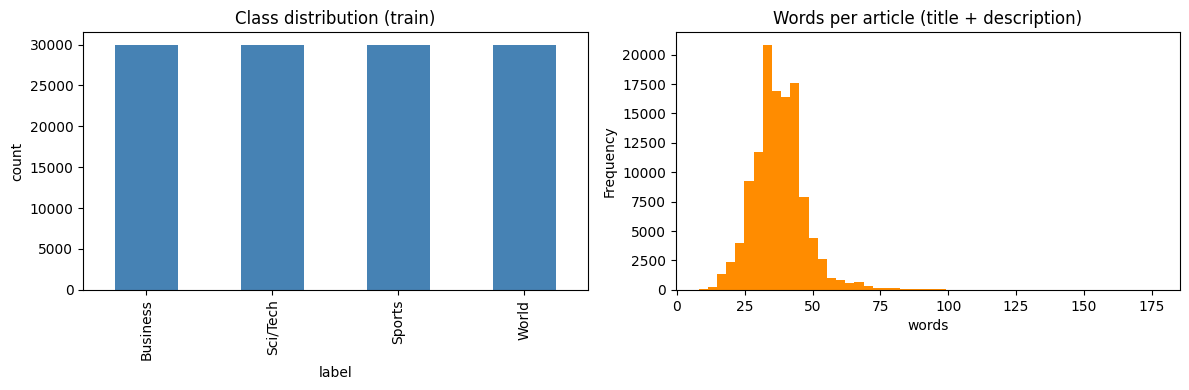

Majority-class baseline test accuracy: 25.00%
Word-count percentiles: {0.5: 37.0, 0.9: 48.0, 0.99: 70.0}


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["label"].map(dict(enumerate(CLASS_NAMES))).value_counts().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Class distribution (train)"); ax[0].set_ylabel("count")
df["text"].str.split().str.len().plot.hist(bins=50, ax=ax[1], color="darkorange")
ax[1].set_title("Words per article (title + description)"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.show()

majority = df["label"].value_counts().idxmax()
baseline_acc = (test_df["label"] == majority).mean()
print(f"Majority-class baseline test accuracy: {baseline_acc:.2%}")
print("Word-count percentiles:", df["text"].str.split().str.len().quantile([.5, .9, .99]).to_dict())

## 3. Preprocessing
Lower-case, strip HTML-ish escapes, keep alphanumeric tokens. Vocabulary is built **only from the training split**. Sequences are truncated to `MAX_LEN` tokens; true lengths are kept so the LSTM can use `pack_padded_sequence` (padding never affects the final hidden state).

In [4]:
def tokenize(text):
    text = text.lower().replace("\\", " ")
    text = re.sub(r"&lt;.*?&gt;|&\w+;|#\d+;", " ", text)   # html escapes / tags
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", text)

train_df, val_df = train_test_split(df, test_size=0.1, stratify=df["label"], random_state=SEED)
print("train:", len(train_df), " val:", len(val_df), " test:", len(test_df))

train_tokens = train_df["text"].map(tokenize)
counter = Counter(tok for toks in train_tokens for tok in toks)

MAX_VOCAB, MIN_FREQ, MAX_LEN = 30000, 2, 80
PAD, UNK = 0, 1
itos = ["<pad>", "<unk>"] + [w for w, c in counter.most_common(MAX_VOCAB) if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
print("vocabulary size:", len(stoi))
print("example:", tokenize(train_df["text"].iloc[0])[:20])

train: 108000  val: 12000  test: 7600
vocabulary size: 30002
example: ['10', 'seconds', 'that', 'change', 'everything', 'athens', 'ten', 'seconds', 'barely', 'time', 'enough', 'to', 'tie', 'a', 'shoe', 'wash', 'a', 'glass', 'get', 'the']


In [5]:
class NewsDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_len=MAX_LEN):
        self.seqs = [[vocab.get(t, UNK) for t in tokenize(x)][:max_len] or [UNK] for x in texts]
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.seqs[i], self.labels[i]

def collate(batch):
    seqs, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])
    padded = torch.full((len(seqs), lengths.max()), PAD, dtype=torch.long)
    for i, s in enumerate(seqs):
        padded[i, :len(s)] = torch.tensor(s)
    return padded, lengths, torch.tensor(labels)

def make_loaders(vocab, batch_size=128):
    sets = [NewsDataset(d["text"], d["label"], vocab) for d in (train_df, val_df, test_df)]
    return (DataLoader(sets[0], batch_size, shuffle=True, collate_fn=collate),
            DataLoader(sets[1], 512, collate_fn=collate),
            DataLoader(sets[2], 512, collate_fn=collate))

train_dl, val_dl, test_dl = make_loaders(stoi)
xb, lb, yb = next(iter(train_dl)); print("batch:", xb.shape, lb[:8].tolist(), yb[:8].tolist())

batch: torch.Size([128, 65]) [38, 37, 37, 39, 45, 50, 47, 49] [0, 2, 1, 2, 3, 2, 0, 2]


## 4. Model: `nn.Embedding → nn.LSTM → nn.Linear`
The classifier uses the LSTM's final hidden state (both directions concatenated when bidirectional) and passes it to a single linear layer.

In [6]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 num_layers=1, bidirectional=False, dropout=0.3):
        super().__init__()
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                            bidirectional=bidirectional, dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * (2 if bidirectional else 1), num_classes)

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)                      # h: (layers*dirs, B, H)
        h = torch.cat([h[-2], h[-1]], dim=1) if self.bidirectional else h[-1]
        return self.fc(self.dropout(h))

In [7]:
def evaluate(model, loader):
    model.eval(); preds, ys, loss_sum = [], [], 0.0
    with torch.no_grad():
        for x, l, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x, l)
            loss_sum += nn.functional.cross_entropy(out, y, reduction="sum").item()
            preds.append(out.argmax(1).cpu()); ys.append(y.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return loss_sum / len(ys), accuracy_score(ys, preds), preds, ys

def train_model(model, epochs, lr, save_path, weight_decay=0.0):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=1)
    hist, best = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}, 0.0
    for ep in range(1, epochs + 1):
        model.train(); t0, tl, tc, n = time.time(), 0.0, 0, 0
        for x, l, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x, l)
            loss = nn.functional.cross_entropy(out, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # avoid exploding gradients
            opt.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        vl, va, _, _ = evaluate(model, val_dl)
        sched.step(va)
        for k, v in zip(hist, (tl / n, tc / n, vl, va)): hist[k].append(v)
        flag = ""
        if va > best:
            best = va; torch.save(model.state_dict(), save_path); flag = "  <- best, saved"
        print(f"epoch {ep:2d} | train loss {tl/n:.4f} acc {tc/n:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.1f}s{flag}")
    model.load_state_dict(torch.load(save_path, map_location=device))
    return hist

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for k in ("train_loss", "val_loss"): ax[0].plot(range(1, len(hist[k]) + 1), hist[k], marker="o", label=k)
    for k in ("train_acc", "val_acc"):   ax[1].plot(range(1, len(hist[k]) + 1), hist[k], marker="o", label=k)
    ax[0].set_title(f"{title} — loss"); ax[1].set_title(f"{title} — accuracy")
    for a in ax: a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

def report(model, title):
    _, acc, preds, ys = evaluate(model, test_dl)
    print(f"{title} — TEST ACCURACY: {acc:.2%}\n")
    print(classification_report(ys, preds, target_names=CLASS_NAMES, digits=4))
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(confusion_matrix(ys, preds), annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"{title} — confusion matrix (test)")
    plt.tight_layout(); plt.show()
    return acc

## LSTM
Bidirectional single-layer LSTM, 128-d embeddings, 128 hidden units per direction, dropout 0.3, Adam (lr 1e-3), gradient clipping, best epoch selected on the validation set.

In [8]:
torch.manual_seed(SEED)
model_a = LSTMClassifier(len(stoi), embed_dim=128, hidden_dim=128, num_classes=4,
                         bidirectional=True, dropout=0.3)
print(model_a)
print("trainable parameters:", sum(p.numel() for p in model_a.parameters() if p.requires_grad))
hist_a = train_model(model_a, epochs=6, lr=1e-3, save_path="ag_news_lstm.pt")

LSTMClassifier(
  (embedding): Embedding(30002, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=4, bias=True)
)
trainable parameters: 4105476
epoch  1 | train loss 0.5975 acc 0.7717 | val loss 0.4071 acc 0.8739 | 28.4s  <- best, saved
epoch  2 | train loss 0.3375 acc 0.8847 | val loss 0.3184 acc 0.8982 | 28.8s  <- best, saved
epoch  3 | train loss 0.2765 acc 0.9055 | val loss 0.2988 acc 0.9062 | 28.4s  <- best, saved
epoch  4 | train loss 0.2408 acc 0.9177 | val loss 0.3147 acc 0.9085 | 48.2s  <- best, saved
epoch  5 | train loss 0.2154 acc 0.9262 | val loss 0.3098 acc 0.9053 | 39.0s
epoch  6 | train loss 0.1953 acc 0.9322 | val loss 0.3089 acc 0.9105 | 26.8s  <- best, saved


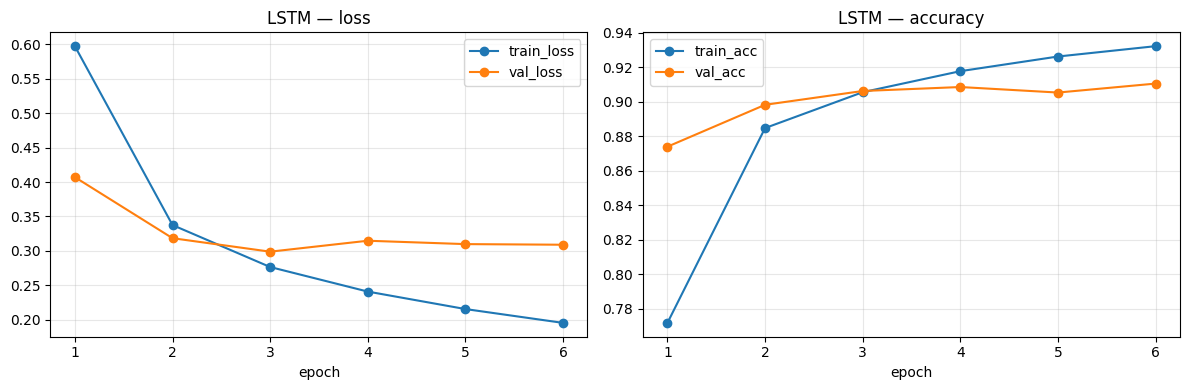

LSTM — TEST ACCURACY: 90.63%

              precision    recall  f1-score   support

       World     0.9432    0.8911    0.9164      1900
      Sports     0.9462    0.9816    0.9636      1900
    Business     0.8359    0.9089    0.8709      1900
    Sci/Tech     0.9067    0.8437    0.8740      1900

    accuracy                         0.9063      7600
   macro avg     0.9080    0.9063    0.9062      7600
weighted avg     0.9080    0.9063    0.9062      7600



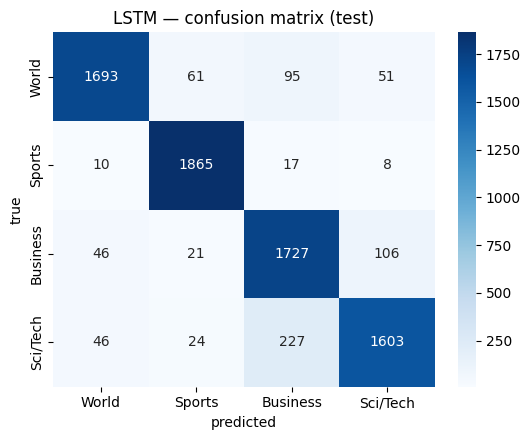

In [9]:
plot_history(hist_a, "LSTM")
acc_a = report(model_a, "LSTM")

## 5. Results summary

In [13]:
TARGET = 0.88
summary = pd.DataFrame({
    "model": ["Majority-class baseline", "LSTM (submission)"],
    "test_accuracy": [baseline_acc, acc_a],
})
summary["beats_baseline"] = summary["test_accuracy"] > baseline_acc
summary["meets_target_88%"] = summary["test_accuracy"] >= TARGET
summary["test_accuracy"] = summary["test_accuracy"].map("{:.2%}".format)
summary

,model,test_accuracy,beats_baseline,meets_target_88%
0,Majority-class baseline,25.00%,False,False
1,LSTM (submission),90.63%,True,True


### Conclusion
- **Submission — LSTM: 90.63% test accuracy**, above the 88% target and far above the 25% majority baseline. Architecture: `nn.Embedding → nn.LSTM (bidirectional) → nn.Linear`, trained from scratch with no pretrained weights. The best validation epoch is saved to `ag_news_lstm.pt`.
- What helped: a vocabulary built from the AG News training split, packed sequences (so padding never reaches the final hidden state), bidirectional encoding, dropout, gradient clipping and picking the best epoch on a held-out validation split.
- Most errors are Business ↔ Sci/Tech confusions, the two topics whose wording overlaps most (see the confusion matrix).